
# Classification d'occupation du sol à partir d'images satellites

**Dataset :** EuroSAT/RGB

**Classes :** Forest, Residential, River

**Objectif :** Comparer trois modèles de classification d'images :
- k-Nearest Neighbors (k-NN)
- Classifieur linéaire Softmax
- Convolutional Neural Network (CNN)

**Protocole expérimental :**
- 900 images (300 par classe)
- Résolution : 32 × 32 RGB
- Train : 60 %
- Validation : 20 %
- Test : 20 %

**Métriques :** Accuracy, Precision macro, Recall macro, F1-score macro et matrice de confusion.


In [2]:

import sys
import numpy as np
import matplotlib
import sklearn
import tensorflow as tf

print("Python :", sys.version.split()[0])
print("NumPy :", np.__version__)
print("Matplotlib :", matplotlib.__version__)
print("Scikit-learn :", sklearn.__version__)
print("TensorFlow :", tf.__version__)

print("\nGPU disponible :", tf.config.list_physical_devices("GPU"))


Python : 3.13.18
NumPy : 2.4.6
Matplotlib : 3.10.0
Scikit-learn : 1.6.1
TensorFlow : 2.21.0

GPU disponible : []


In [3]:

import tensorflow as tf
import numpy as np
import sklearn
import PIL

print("TensorFlow :", tf.__version__)
print("NumPy :", np.__version__)
print("Scikit-learn :", sklearn.__version__)
print("Pillow :", PIL.__version__)


TensorFlow : 2.21.0
NumPy : 2.4.6
Scikit-learn : 1.6.1
Pillow : 11.3.0


In [4]:

import requests
from pathlib import Path

url = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1"
destination = Path("/content/EuroSAT_RGB.zip")

with requests.get(url, stream=True, timeout=(15, 120)) as response:
    response.raise_for_status()

    with open(destination, "wb") as fichier:
        for bloc in response.iter_content(chunk_size=1024 * 1024):
            if bloc:
                fichier.write(bloc)

print("Téléchargement terminé !")
print("Taille :", round(destination.stat().st_size / 1024**2, 2), "Mo")


Téléchargement terminé !
Taille : 90.27 Mo


In [5]:

import zipfile
from pathlib import Path

# Chemin de l'archive téléchargée
zip_path = Path("/content/EuroSAT_RGB.zip")

# Dossier où extraire les images
extract_path = Path("/content/eurosat_data")

# Extraction
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction terminée !")

# Afficher les premiers éléments du dossier
print("\nContenu du dossier :")
for element in sorted(extract_path.iterdir()):
    print(element.name)


Extraction terminée !

Contenu du dossier :
EuroSAT_RGB


In [6]:

# Classes retenues pour notre projet
classes = ["Forest", "Residential", "River"]

# Localiser automatiquement les dossiers des classes
class_dirs = {}

for classe in classes:
    dossiers = [
        p for p in extract_path.rglob(classe)
        if p.is_dir()
    ]

    if len(dossiers) != 1:
        raise ValueError(
            f"{classe} : {len(dossiers)} dossier(s) trouvé(s)"
        )

    class_dirs[classe] = dossiers[0]

# Compter les images
for classe, dossier in class_dirs.items():
    images = list(dossier.glob("*.jpg"))
    print(f"{classe} : {len(images)} images")


Forest : 3000 images
Residential : 3000 images
River : 2500 images


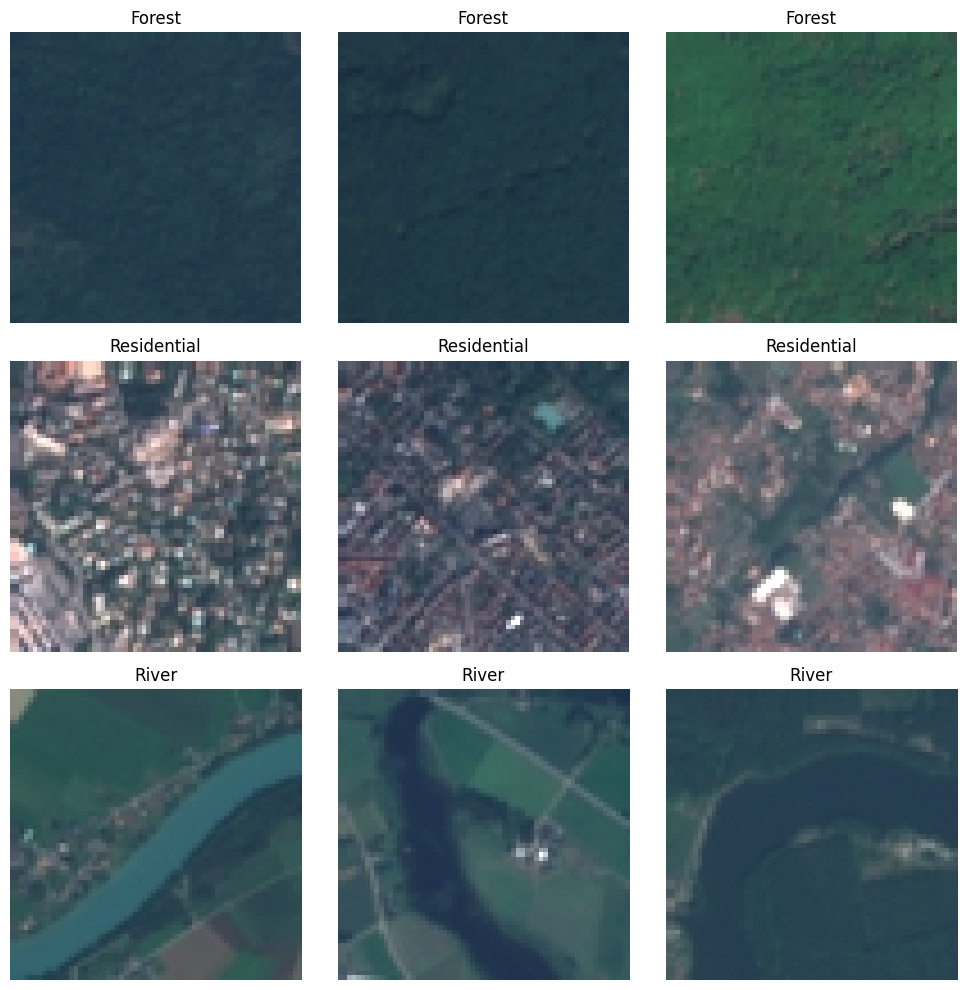

In [7]:

import matplotlib.pyplot as plt
from PIL import Image
import random

# Fixer une graine pour obtenir les mêmes images
random.seed(42)

# Créer une figure avec 3 lignes et 3 colonnes
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for i, classe in enumerate(classes):

    # Récupérer les chemins des images
    images = sorted(class_dirs[classe].glob("*.jpg"))

    # Choisir 3 images aléatoires
    exemples = random.sample(images, 3)

    for j, chemin in enumerate(exemples):

        # Ouvrir l'image en RGB
        image = Image.open(chemin).convert("RGB")

        # Afficher l'image
        axes[i, j].imshow(image)

        # Ajouter le nom de la classe
        axes[i, j].set_title(classe)

        # Masquer les axes
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


In [8]:

import numpy as np

# Choisir une image Forest
chemin = sorted(class_dirs["Forest"].glob("*.jpg"))[0]

image = Image.open(chemin).convert("RGB")

# Convertir l'image en tableau NumPy
image_array = np.array(image)

print("Dimensions de l'image :", image_array.shape)
print("Type des pixels :", image_array.dtype)
print("Valeur minimale :", image_array.min())
print("Valeur maximale :", image_array.max())

# Afficher les valeurs RGB du premier pixel
print("Premier pixel RGB :", image_array[0, 0])


Dimensions de l'image : (64, 64, 3)
Type des pixels : uint8
Valeur minimale : 30
Valeur maximale : 98
Premier pixel RGB : [40 63 79]


In [9]:

from pathlib import Path
import random

# Fixer la graine aléatoire
random.seed(42)

# Classes de notre projet
classes = ["Forest", "Residential", "River"]

# Listes pour stocker les images et leurs labels
image_paths = []
labels = []

# Parcourir les trois classes
for label, classe in enumerate(classes):

    # Récupérer les images de la classe
    images = sorted(class_dirs[classe].glob("*.jpg"))

    # Sélectionner 300 images aléatoires
    selected_images = random.sample(images, 300)

    # Ajouter les chemins des images
    image_paths.extend(selected_images)

    # Ajouter les étiquettes correspondantes
    labels.extend([label] * 300)

    print(f"{classe} : {len(selected_images)} images")

print("\nNombre total d'images :", len(image_paths))
print("Nombre total de labels :", len(labels))


Forest : 300 images
Residential : 300 images
River : 300 images

Nombre total d'images : 900
Nombre total de labels : 900


In [10]:

import numpy as np

# Convertir les labels en tableau NumPy
y = np.array(labels)

# Compter les images de chaque classe
unique, counts = np.unique(y, return_counts=True)

for label, count in zip(unique, counts):
    print(f"{classes[label]} : {count} images")

# Vérifications automatiques
assert len(image_paths) == 900
assert len(labels) == 900
assert all(count == 300 for count in counts)

print("\nDataset équilibré et vérifié !")


Forest : 300 images
Residential : 300 images
River : 300 images

Dataset équilibré et vérifié !


In [11]:

from sklearn.model_selection import train_test_split

# Première séparation : 60 % Train, 40 % temporaire
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.40,
    random_state=42,
    stratify=labels
)

# Deuxième séparation : 20 % Validation, 20 % Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train :", len(X_train), "images")
print("Validation :", len(X_val), "images")
print("Test :", len(X_test), "images")


Train : 540 images
Validation : 180 images
Test : 180 images


In [12]:

import numpy as np

def afficher_repartition(nom, y):
    print(f"\n{nom} :")

    unique, counts = np.unique(y, return_counts=True)

    for label, count in zip(unique, counts):
        print(f"  {classes[label]} : {count} images")

afficher_repartition("Train", y_train)
afficher_repartition("Validation", y_val)
afficher_repartition("Test", y_test)

# Vérifier les tailles et l'absence de chevauchement
assert (len(X_train), len(X_val), len(X_test)) == (540, 180, 180)

assert len(set(X_train) & set(X_val)) == 0
assert len(set(X_train) & set(X_test)) == 0
assert len(set(X_val) & set(X_test)) == 0

print("\nSéparation vérifiée !")



Train :
  Forest : 180 images
  Residential : 180 images
  River : 180 images

Validation :
  Forest : 60 images
  Residential : 60 images
  River : 60 images

Test :
  Forest : 60 images
  Residential : 60 images
  River : 60 images

Séparation vérifiée !


In [13]:

from PIL import Image
import numpy as np

def preprocess_image(image_path):

    # 1. Ouvrir l'image en RGB
    image = Image.open(image_path).convert("RGB")

    # 2. Redimensionner à 32 × 32
    image = image.resize((32, 32))

    # 3. Convertir en tableau NumPy
    image_array = np.array(image, dtype=np.float32)

    # 4. Normaliser les pixels entre 0 et 1
    image_array = image_array / 255.0

    return image_array


In [14]:

# Prétraitement des images Train
X_train_images = np.array([
    preprocess_image(path) for path in X_train
])

# Prétraitement des images Validation
X_val_images = np.array([
    preprocess_image(path) for path in X_val
])

# Prétraitement des images Test
X_test_images = np.array([
    preprocess_image(path) for path in X_test
])

# Convertir les labels en tableaux NumPy
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

# Afficher les dimensions
print("Train :", X_train_images.shape)
print("Validation :", X_val_images.shape)
print("Test :", X_test_images.shape)

print("\nValeur minimale :", X_train_images.min())
print("Valeur maximale :", X_train_images.max())


Train : (540, 32, 32, 3)
Validation : (180, 32, 32, 3)
Test : (180, 32, 32, 3)

Valeur minimale : 0.078431375
Valeur maximale : 1.0


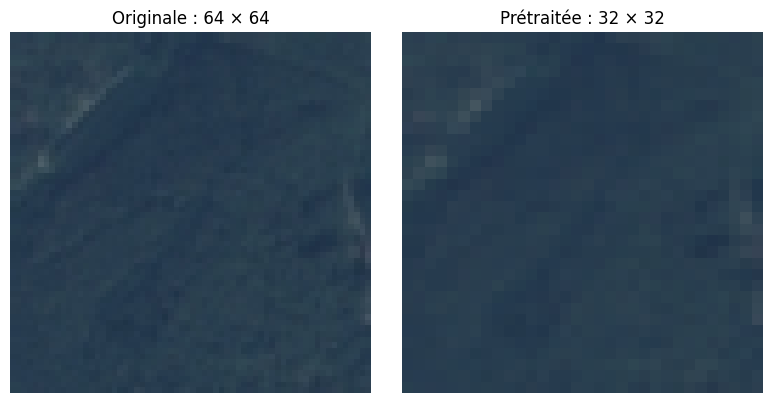

In [15]:

import matplotlib.pyplot as plt

# Première image de Train
original = Image.open(X_train[0]).convert("RGB")

# Même image après prétraitement
processed = X_train_images[0]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(original)
axes[0].set_title("Originale : 64 × 64")
axes[0].axis("off")

axes[1].imshow(processed)
axes[1].set_title("Prétraitée : 32 × 32")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [16]:

# Transformer chaque image en vecteur de 3072 valeurs
X_train_flat = X_train_images.reshape(540, -1)
X_val_flat = X_val_images.reshape(180, -1)
X_test_flat = X_test_images.reshape(180, -1)

print("Train Flatten :", X_train_flat.shape)
print("Validation Flatten :", X_val_flat.shape)
print("Test Flatten :", X_test_flat.shape)


Train Flatten : (540, 3072)
Validation Flatten : (180, 3072)
Test Flatten : (180, 3072)


In [17]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. Créer le modèle k-NN
knn = KNeighborsClassifier(
    n_neighbors=3,
    metric="euclidean"
)

# 2. Entraîner le modèle sur Train
knn.fit(X_train_flat, y_train)

# 3. Prédire les classes sur Validation
y_val_pred = knn.predict(X_val_flat)

# 4. Calculer l'Accuracy
accuracy = accuracy_score(y_val, y_val_pred)

print("Accuracy Validation :", round(accuracy * 100, 2), "%")


Accuracy Validation : 79.44 %


In [18]:

for i in range(10):
    vraie_classe = classes[y_val[i]]
    prediction = classes[y_val_pred[i]]

    print(
        f"Image {i+1} : "
        f"Réelle = {vraie_classe} | "
        f"Prédite = {prediction}"
    )


Image 1 : Réelle = River | Prédite = River
Image 2 : Réelle = Residential | Prédite = Residential
Image 3 : Réelle = Forest | Prédite = Forest
Image 4 : Réelle = Residential | Prédite = Residential
Image 5 : Réelle = River | Prédite = Forest
Image 6 : Réelle = River | Prédite = Residential
Image 7 : Réelle = River | Prédite = River
Image 8 : Réelle = Residential | Prédite = Residential
Image 9 : Réelle = Residential | Prédite = Residential
Image 10 : Réelle = Residential | Prédite = Residential


In [19]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import pandas as pd

# Hyperparamètres à tester
k_values = [1, 3, 5, 7, 9]

distances = {
    "L1": "manhattan",
    "L2": "euclidean"
}

# Stocker les résultats
results = []

# Tester les deux distances
for distance_name, metric in distances.items():

    # Tester les cinq valeurs de K
    for k in k_values:

        # Créer le modèle
        model = KNeighborsClassifier(
            n_neighbors=k,
            metric=metric
        )

        # Entraîner sur Train
        model.fit(X_train_flat, y_train)

        # Prédire sur Validation
        predictions = model.predict(X_val_flat)

        # Calculer l'Accuracy
        accuracy = accuracy_score(y_val, predictions)

        # Enregistrer le résultat
        results.append({
            "K": k,
            "Distance": distance_name,
            "Accuracy": accuracy
        })

# Créer un tableau des résultats
results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))


 K Distance  Accuracy
 1       L1  0.811111
 3       L1  0.794444
 5       L1  0.777778
 7       L1  0.766667
 9       L1  0.755556
 1       L2  0.788889
 3       L2  0.794444
 5       L2  0.755556
 7       L2  0.744444
 9       L2  0.744444


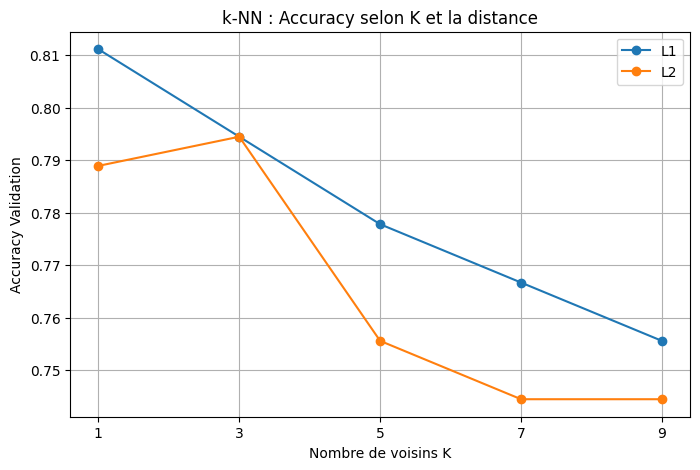

In [20]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for distance in ["L1", "L2"]:

    subset = results_df[
        results_df["Distance"] == distance
    ]

    plt.plot(
        subset["K"],
        subset["Accuracy"],
        marker="o",
        label=distance
    )

plt.xlabel("Nombre de voisins K")
plt.ylabel("Accuracy Validation")
plt.title("k-NN : Accuracy selon K et la distance")
plt.xticks(k_values)
plt.legend()
plt.grid(True)

plt.show()


In [21]:

# Trouver la ligne avec la meilleure Accuracy
best_index = results_df["Accuracy"].idxmax()

best_result = results_df.loc[best_index]

best_k = int(best_result["K"])
best_distance = best_result["Distance"]
best_accuracy = best_result["Accuracy"]

print("Meilleur K :", best_k)
print("Meilleure distance :", best_distance)
print(
    "Meilleure Accuracy Validation :",
    round(best_accuracy * 100, 2),
    "%"
)


Meilleur K : 1
Meilleure distance : L1
Meilleure Accuracy Validation : 81.11 %


In [22]:

import tensorflow as tf

# Fixer la graine pour la reproductibilité
tf.keras.utils.set_random_seed(42)

# Construire le modèle linéaire Softmax
softmax_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(3072,)),
    tf.keras.layers.Dense(3, activation="softmax")
])

# Afficher l'architecture
softmax_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 3)              │         9,219 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,219 (36.01 KB)

 Trainable params: 9,219 (36.01 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:

softmax_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modèle compilé avec succès !")


Modèle compilé avec succès !


In [24]:

history_softmax = softmax_model.fit(
    X_train_flat,
    y_train,
    validation_data=(X_val_flat, y_val),
    epochs=30,
    batch_size=32,
    verbose=1
)


Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.4426 - loss: 1.0527 - val_accuracy: 0.6722 - val_loss: 0.8852
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6463 - loss: 0.8572 - val_accuracy: 0.7167 - val_loss: 0.7739
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7000 - loss: 0.7674 - val_accuracy: 0.7500 - val_loss: 0.6861
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7333 - loss: 0.7145 - val_accuracy: 0.7778 - val_loss: 0.6416
Epoch 5/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7500 - loss: 0.6769 - val_accuracy: 0.7667 - val_loss: 0.6083
Epoch 6/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7630 - loss: 0.6482 - val_accuracy: 0.7778 - val_loss: 0.5846
Epoch 7/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7648 - loss: 0.6249 - val_accuracy: 0.7944 - val_loss: 0.5664
Epoch 8/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7704 - loss: 0.6057 - val_accuracy: 0.8056 - val_los

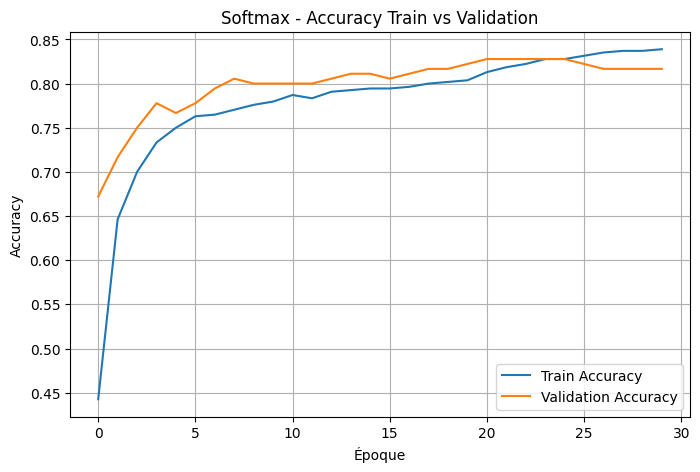

In [25]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_softmax.history["accuracy"],
    label="Train Accuracy"
)

plt.plot(
    history_softmax.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.title("Softmax - Accuracy Train vs Validation")
plt.legend()
plt.grid(True)
plt.show()


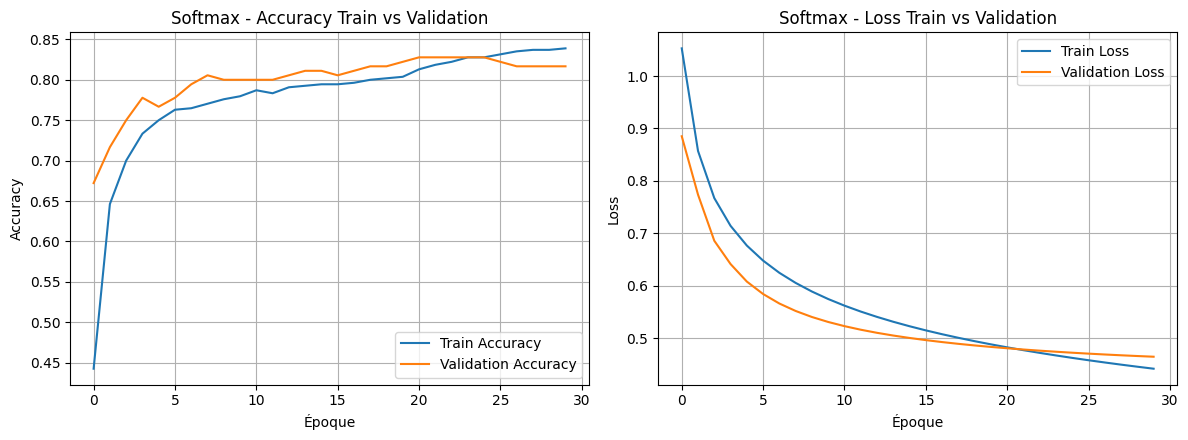

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4.5))

# ==========================================
# 1. Graphique Accuracy
# ==========================================
plt.subplot(1, 2, 1)

plt.plot(
    history_softmax.history["accuracy"],
    label="Train Accuracy"
)

plt.plot(
    history_softmax.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.title("Softmax - Accuracy Train vs Validation")
plt.legend()
plt.grid(True)

# ==========================================
# 2. Graphique Loss
# ==========================================
plt.subplot(1, 2, 2)

plt.plot(
    history_softmax.history["loss"],
    label="Train Loss"
)

plt.plot(
    history_softmax.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Époque")
plt.ylabel("Loss")
plt.title("Softmax - Loss Train vs Validation")
plt.legend()
plt.grid(True)

# ==========================================
# 3. Affichage et sauvegarde
# ==========================================
plt.tight_layout()

plt.savefig(
    "softmax_accuracy_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:

import numpy as np

val_accuracies = history_softmax.history["val_accuracy"]

best_epoch = np.argmax(val_accuracies) + 1
best_val_accuracy = np.max(val_accuracies)

print("Meilleure époque :", best_epoch)
print(
    "Meilleure Accuracy Validation :",
    round(best_val_accuracy * 100, 2),
    "%"
)


Meilleure époque : 21
Meilleure Accuracy Validation : 82.78 %


In [28]:

import tensorflow as tf

tf.keras.utils.set_random_seed(42)

softmax_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(3072,)),
    tf.keras.layers.Dense(3, activation="softmax")
])

softmax_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Sauvegarder les meilleurs poids
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="/content/best_softmax.weights.h5",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    save_weights_only=True
)

history_softmax = softmax_model.fit(
    X_train_flat,
    y_train,
    validation_data=(X_val_flat, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[checkpoint],
    verbose=1
)

# Restaurer les meilleurs poids
softmax_model.load_weights("/content/best_softmax.weights.h5")

print("Meilleurs poids Softmax restaurés !")


Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.4426 - loss: 1.0527 - val_accuracy: 0.6722 - val_loss: 0.8852
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6463 - loss: 0.8572 - val_accuracy: 0.7167 - val_loss: 0.7739
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7000 - loss: 0.7674 - val_accuracy: 0.7500 - val_loss: 0.6861
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7333 - loss: 0.7145 - val_accuracy: 0.7778 - val_loss: 0.6416
Epoch 5/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7500 - loss: 0.6769 - val_accuracy: 0.7667 - val_loss: 0.6083
Epoch 6/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7630 - loss: 0.6482 - val_accuracy: 0.7778 - val_loss: 0.5846
Epoch 7/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7648 - loss: 0.6249 - val_accuracy: 0.7944 - val_loss: 0.5664
Epoch 8/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7704 - loss: 0.6057 - val_accuracy: 0.8056 - val_l

In [29]:

val_loss, val_accuracy = softmax_model.evaluate(
    X_val_flat,
    y_val,
    verbose=0
)

print(
    "Accuracy Validation du modèle conservé :",
    round(val_accuracy * 100, 2),
    "%"
)


Accuracy Validation du modèle conservé : 82.78 %


In [30]:

import os

# 1. Vérifier les variables nécessaires
variables = [
    "softmax_model",
    "history_softmax",
    "X_val_flat",
    "y_val"
]

for variable in variables:
    if variable in globals():
        print(f"{variable} : disponible")
    else:
        print(f"{variable} : ABSENTE")

# 2. Vérifier le fichier des meilleurs poids
checkpoint_path = "/content/best_softmax.weights.h5"

if os.path.isfile(checkpoint_path):
    print("\nFichier Softmax : TROUVÉ")
    print(
        "Taille :",
        round(os.path.getsize(checkpoint_path) / 1024, 2),
        "Ko"
    )
else:
    print("\nFichier Softmax : INTROUVABLE")


softmax_model : disponible
history_softmax : disponible
X_val_flat : disponible
y_val : disponible

Fichier Softmax : TROUVÉ
Taille : 123.48 Ko


In [31]:

# 1. Charger les meilleurs poids sauvegardés
softmax_model.load_weights(
    "/content/best_softmax.weights.h5"
)

# 2. Évaluer le modèle restauré sur Validation
val_loss, val_accuracy = softmax_model.evaluate(
    X_val_flat,
    y_val,
    verbose=0
)

# 3. Afficher les résultats
print("Meilleurs poids restaurés !")
print("Validation Loss :", round(val_loss, 4))
print(
    "Validation Accuracy :",
    round(val_accuracy * 100, 2),
    "%"
)


Meilleurs poids restaurés !
Validation Loss : 0.4812
Validation Accuracy : 82.78 %


In [32]:

import tensorflow as tf

# Reproductibilité
tf.keras.utils.set_random_seed(42)

# Architecture CNN imposée
cnn_model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(
        64, activation="relu"
    ),

    tf.keras.layers.Dense(
        3, activation="softmax"
    )
])

cnn_model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,107 (652.76 KB)

 Trainable params: 167,107 (652.76 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:

# Compilation du CNN
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN compilé avec succès !")


CNN compilé avec succès !


In [34]:

import tensorflow as tf

# Vérifier les dimensions des données
print("Train :", X_train_images.shape)
print("Validation :", X_val_images.shape)

# Sauvegarder les meilleurs poids du CNN
checkpoint_cnn = tf.keras.callbacks.ModelCheckpoint(
    filepath="/content/best_cnn.weights.h5",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    save_weights_only=True
)

# Entraîner le CNN
history_cnn = cnn_model.fit(
    X_train_images,
    y_train,
    validation_data=(X_val_images, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[checkpoint_cnn],
    verbose=1
)

print("Entraînement du CNN terminé !")


Train : (540, 32, 32, 3)
Validation : (180, 32, 32, 3)
Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy: 0.5315 - loss: 0.9147 - val_accuracy: 0.8278 - val_loss: 0.6376
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 90ms/step - accuracy: 0.7926 - loss: 0.5506 - val_accuracy: 0.8611 - val_loss: 0.4248
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - accuracy: 0.7889 - loss: 0.4697 - val_accuracy: 0.8500 - val_loss: 0.3857
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.8259 - loss: 0.4329 - val_accuracy: 0.8500 - val_loss: 0.3813
Epoch 5/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.8093 - loss: 0.4144 - val_accuracy: 0.8500 - val_loss: 0.3662
Epoch 6/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 0.8389 - loss: 0.3841 - val_accuracy: 0.8556 - val_loss: 0.3482
Epoch 7/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.8519 - loss: 0.3623 - val_accuracy: 0.8556 - val_loss: 0.3467
Epoch 8/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - acc

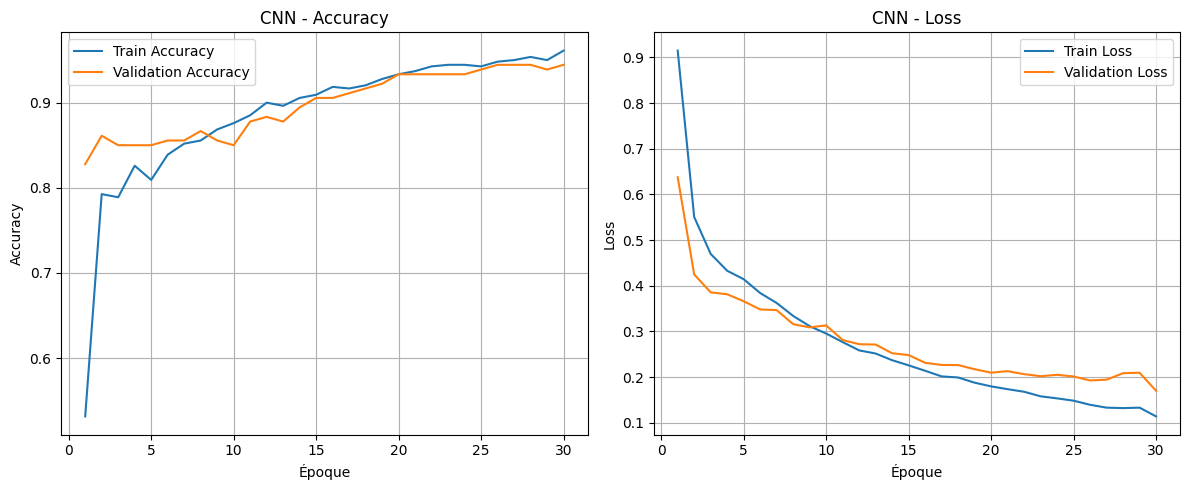

In [35]:

import matplotlib.pyplot as plt

# Historique des 30 époques
epochs = range(1, len(history_cnn.history["accuracy"]) + 1)

plt.figure(figsize=(12, 5))

# Graphique 1 : Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    epochs,
    history_cnn.history["accuracy"],
    label="Train Accuracy"
)

plt.plot(
    epochs,
    history_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.title("CNN - Accuracy")
plt.legend()
plt.grid(True)

# Graphique 2 : Loss
plt.subplot(1, 2, 2)

plt.plot(
    epochs,
    history_cnn.history["loss"],
    label="Train Loss"
)

plt.plot(
    epochs,
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Époque")
plt.ylabel("Loss")
plt.title("CNN - Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [36]:

# Restaurer les meilleurs poids sauvegardés
cnn_model.load_weights("/content/best_cnn.weights.h5")

# Vérifier les performances sur Validation
val_loss, val_accuracy = cnn_model.evaluate(
    X_val_images,
    y_val,
    verbose=0
)

print(f"Validation Accuracy : {val_accuracy:.4f}")
print(f"Validation Loss : {val_loss:.4f}")


Validation Accuracy : 0.9444
Validation Loss : 0.1928


In [37]:

import numpy as np
from sklearn.neighbors import KNeighborsClassifier

# 1. k-NN : meilleur modèle sélectionné
knn_final = KNeighborsClassifier(
    n_neighbors=1,
    metric="manhattan"
)

knn_final.fit(X_train_flat, y_train)

y_pred_knn = knn_final.predict(X_test_flat)

# 2. Softmax : restaurer les meilleurs poids
softmax_model.load_weights(
    "/content/best_softmax.weights.h5"
)

proba_softmax = softmax_model.predict(
    X_test_flat,
    verbose=0
)

y_pred_softmax = np.argmax(
    proba_softmax,
    axis=1
)

# 3. CNN : restaurer les meilleurs poids
cnn_model.load_weights(
    "/content/best_cnn.weights.h5"
)

proba_cnn = cnn_model.predict(
    X_test_images,
    verbose=0
)

y_pred_cnn = np.argmax(
    proba_cnn,
    axis=1
)

# Vérifier les dimensions
print("Vraies classes :", y_test.shape)
print("k-NN :", y_pred_knn.shape)
print("Softmax :", y_pred_softmax.shape)
print("CNN :", y_pred_cnn.shape)


Vraies classes : (180,)
k-NN : (180,)
Softmax : (180,)
CNN : (180,)


In [38]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Regrouper les prédictions
predictions = {
    "k-NN": y_pred_knn,
    "Softmax": y_pred_softmax,
    "CNN": y_pred_cnn
}

# Calculer les métriques
results = []

for model_name, y_pred in predictions.items():

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average="macro",
        zero_division=0
    )

    results.append({
        "Modèle": model_name,
        "Accuracy": accuracy,
        "Precision macro": precision,
        "Recall macro": recall,
        "F1 macro": f1
    })

# Créer un tableau comparatif
df_results = pd.DataFrame(results)

display(df_results.round(4))


,Modèle,Accuracy,Precision macro,Recall macro,F1 macro
0,k-NN,0.7333,0.7402,0.7333,0.7119
1,Softmax,0.7278,0.7294,0.7278,0.7024
2,CNN,0.9167,0.9211,0.9167,0.9167


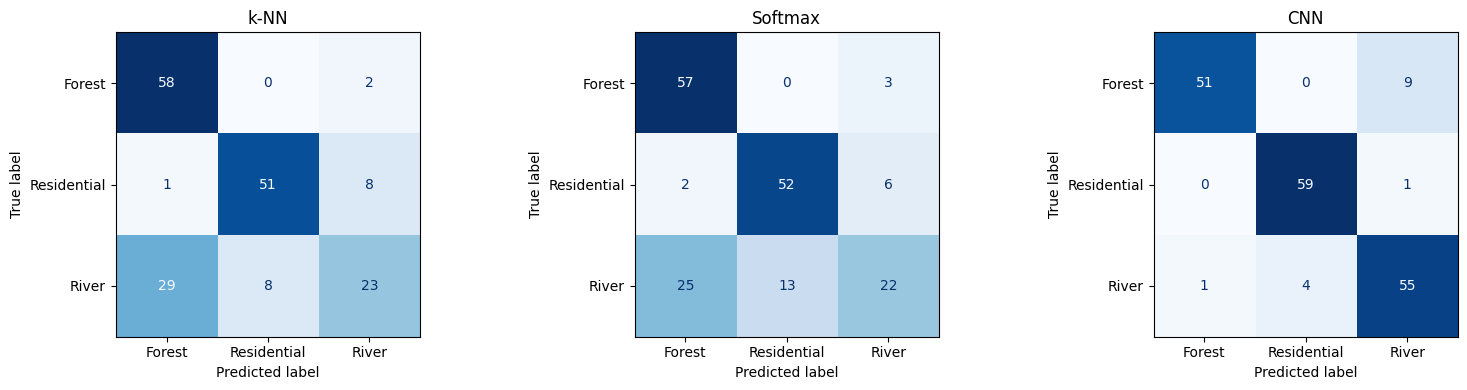

In [39]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Prédictions des trois modèles
predictions = {
    "k-NN": y_pred_knn,
    "Softmax": y_pred_softmax,
    "CNN": y_pred_cnn
}

class_names = ["Forest", "Residential", "River"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (model_name, y_pred) in zip(
    axes, predictions.items()
):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1, 2]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(model_name)

plt.tight_layout()
plt.show()


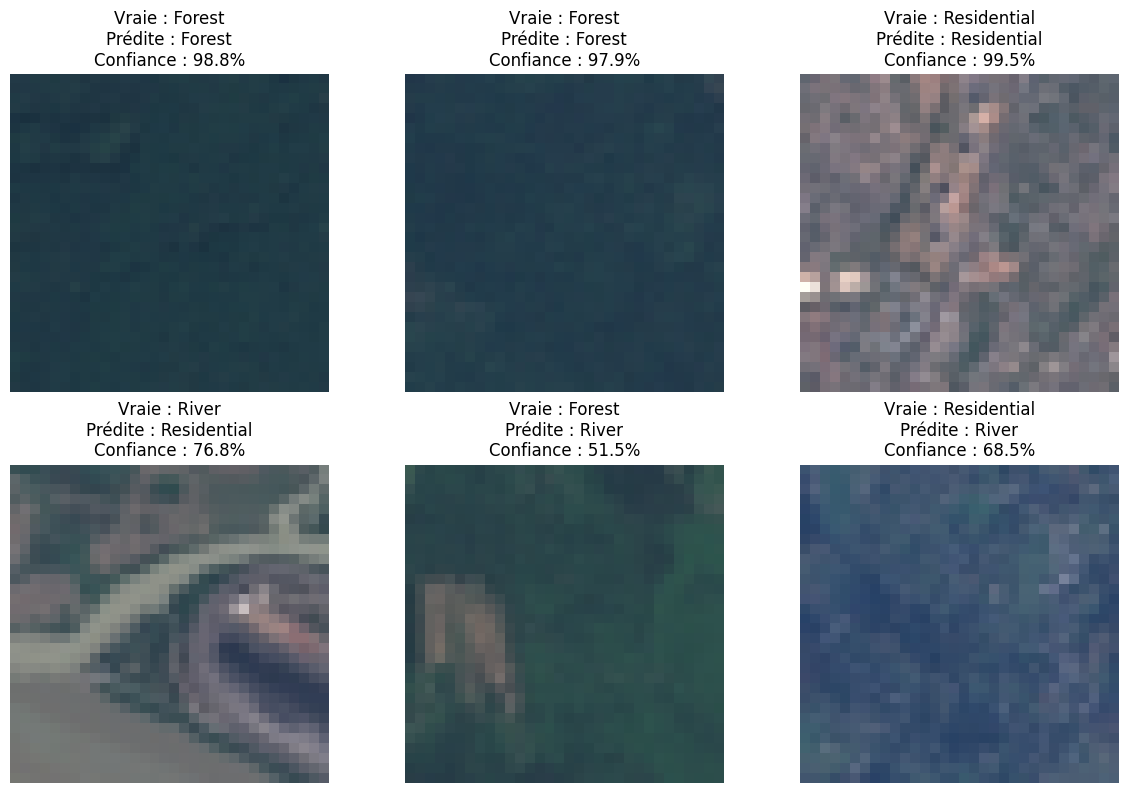

In [40]:

import numpy as np
import matplotlib.pyplot as plt

class_names = ["Forest", "Residential", "River"]

# Identifier les prédictions correctes et incorrectes
correct_indices = np.where(y_pred_cnn == y_test)[0]
error_indices = np.where(y_pred_cnn != y_test)[0]

# Sélectionner 3 images de chaque groupe
correct_examples = correct_indices[:3]
error_examples = error_indices[:3]

selected_indices = np.concatenate([
    correct_examples,
    error_examples
])

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, idx in enumerate(selected_indices):

    ax = axes[i // 3, i % 3]

    ax.imshow(X_test_images[idx])

    true_label = class_names[y_test[idx]]
    predicted_label = class_names[y_pred_cnn[idx]]

    confidence = proba_cnn[idx][y_pred_cnn[idx]] * 100

    ax.set_title(
        f"Vraie : {true_label}\n"
        f"Prédite : {predicted_label}\n"
        f"Confiance : {confidence:.1f}%"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()


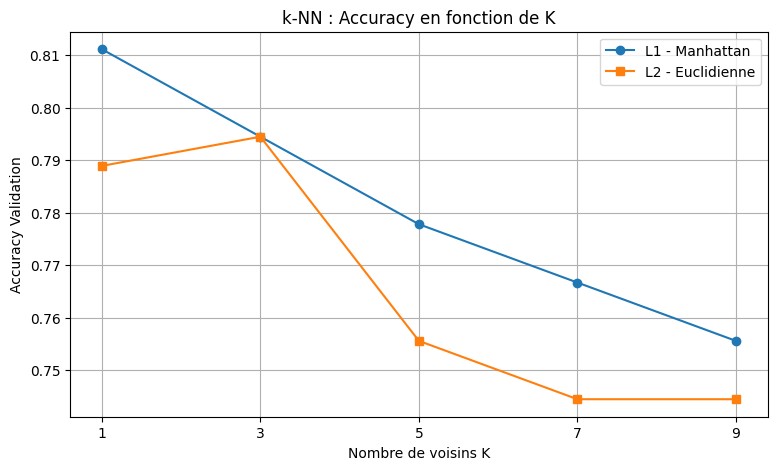

Meilleur K : 1
Meilleure distance : L1
Meilleure Accuracy Validation : 0.8111


In [41]:

import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

k_values = [1, 3, 5, 7, 9]

accuracy_l1 = []
accuracy_l2 = []

for k in k_values:

    # k-NN avec distance Manhattan
    knn_l1 = KNeighborsClassifier(
        n_neighbors=k,
        metric="manhattan"
    )

    knn_l1.fit(X_train_flat, y_train)

    pred_l1 = knn_l1.predict(X_val_flat)

    accuracy_l1.append(
        accuracy_score(y_val, pred_l1)
    )

    # k-NN avec distance Euclidienne
    knn_l2 = KNeighborsClassifier(
        n_neighbors=k,
        metric="euclidean"
    )

    knn_l2.fit(X_train_flat, y_train)

    pred_l2 = knn_l2.predict(X_val_flat)

    accuracy_l2.append(
        accuracy_score(y_val, pred_l2)
    )

# Visualisation
plt.figure(figsize=(9, 5))

plt.plot(
    k_values, accuracy_l1,
    marker="o", label="L1 - Manhattan"
)

plt.plot(
    k_values, accuracy_l2,
    marker="s", label="L2 - Euclidienne"
)

plt.xlabel("Nombre de voisins K")
plt.ylabel("Accuracy Validation")
plt.title("k-NN : Accuracy en fonction de K")
plt.xticks(k_values)
plt.legend()
plt.grid(True)

plt.show()

# Afficher la meilleure configuration
results_knn = [
    (accuracy, k, distance)
    for distance, accuracies in [
        ("L1", accuracy_l1),
        ("L2", accuracy_l2)
    ]
    for k, accuracy in zip(k_values, accuracies)
]

best_accuracy, best_k, best_distance = max(
    results_knn,
    key=lambda x: x[0]
)

print("Meilleur K :", best_k)
print("Meilleure distance :", best_distance)
print(f"Meilleure Accuracy Validation : {best_accuracy:.4f}")
